# Freight Rate Prediction

End-to-end solution: EDA → data quality → features → time-based validation → final model → predictions.

Run top to bottom (`Kernel → Restart & Run All`). Outputs written:
- `validation_predictions.csv` (12,000 rows, `load_id,predicted_rate`)
- `december_chart_predictions.csv` (the December inputs with `predicted_rate` filled)
- `figures/*.png` (EDA, diagnostics and the December forecast)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge

pd.set_option("display.width", 160)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
SEED = 0

DATA = Path("data")

def data_file(name):
    # Accept hyphenated or underscored file names.
    for path in (DATA / name, DATA / name.replace("-", "_")):
        if path.exists():
            return path
    raise FileNotFoundError(f"Put {name} in {DATA.resolve()}/ (see README)")

train = pd.read_csv(data_file("train-test.csv"), parse_dates=["date"])
valid = pd.read_csv(data_file("validation.csv"), parse_dates=["date"])
dec = pd.read_csv(data_file("december-chart-inputs.csv"), parse_dates=["date"])
template = pd.read_csv(data_file("validation-predictions-template.csv"))
print(train.shape, valid.shape, dec.shape, template.shape)
print("train dates", train.date.min().date(), "→", train.date.max().date(), "| validation dates", valid.date.min().date(), "→", valid.date.max().date())
train.head()

(48000, 14) (12000, 13) (31, 7) (12000, 2)
train dates 2025-01-01 → 2025-10-31 | validation dates 2025-11-01 → 2025-12-31


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## 1. Exploratory analysis

In [2]:
display(train.describe().T)
print("missing values:\n", train.isna().sum()[train.isna().sum() > 0])
print("\nequipment mix:\n", train.equipment.value_counts(normalize=True).round(3))
train["rpm"] = train.posted_rate / train.distance
print("\nrate per mile percentiles:\n", train.rpm.quantile([0, .001, .01, .5, .99, .999, 1]).round(2))

,count,mean,min,25%,50%,75%,max,std
pickup_lat,48000.0,35.647545,28.35765,31.98691,35.29479,39.41104,44.30296,4.315285
pickup_lon,48000.0,-90.928964,-121.69849,-98.40059,-88.08915,-83.28506,-69.5,13.482431
delivery_lat,48000.0,35.641175,28.35765,31.98691,35.29479,39.41104,44.30296,4.317199
delivery_lon,48000.0,-90.85731,-121.69849,-98.40059,-87.52871,-83.28506,-69.5,13.476589
distance,48000.0,1135.856654,70.0,550.4,953.3,1645.525,3439.8,728.564416
weight,47700.0,31028.844004,-47500.0,25800.0,31436.5,37018.0,47500.0,9391.44062
date,48000,2025-05-31 19:53:29.399999,2025-01-01 00:00:00,2025-03-18 00:00:00,2025-05-31 00:00:00,2025-08-15 00:00:00,2025-10-31 00:00:00,NaN
market_index,47626.0,1.083387,0.67639,0.94967,1.0558,1.21959,1.46778,0.168091
quote_signal,48000.0,2.062468,0.69228,1.89103,2.05575,2.221685,3.61035,0.291391
posted_rate,48000.0,2373.980682,57.22,1251.555,2030.76,3330.75,25533.0,1486.493245


missing values:
 weight          300
market_index    374
dtype: int64

equipment mix:
 equipment
Dry Van    0.567
Reefer     0.251
Flatbed    0.182
Name: proportion, dtype: float64

rate per mile percentiles:
 0.000     0.33
0.001     0.44
0.010     1.67
0.500     2.15
0.990     3.18
0.999    10.07
1.000    14.13
Name: rpm, dtype: float64


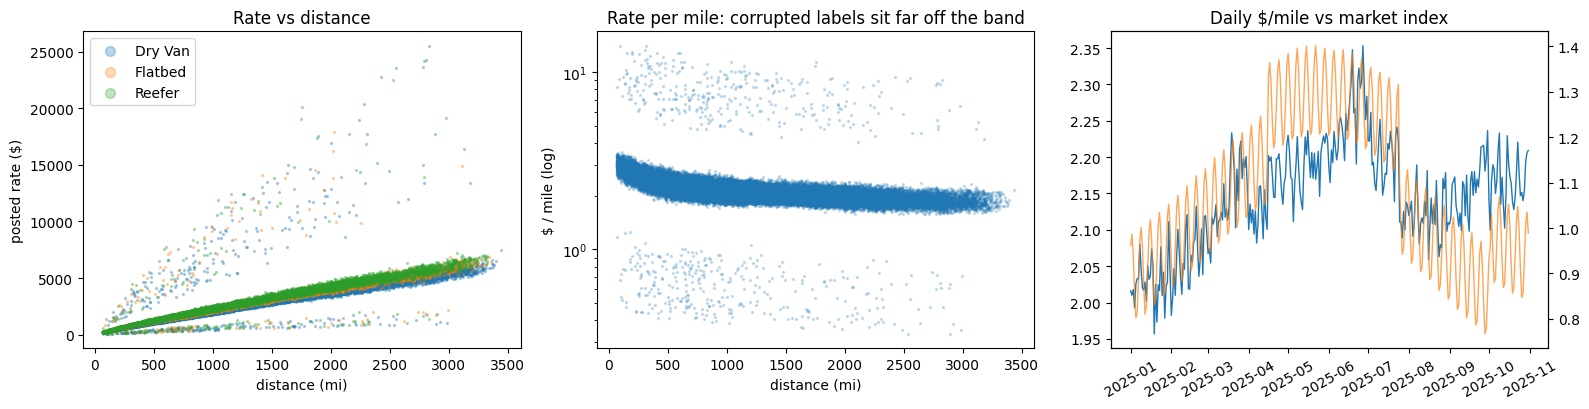

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for eq, g in train.groupby("equipment"):
    ax[0].scatter(g.distance, g.posted_rate, s=2, alpha=.3, label=eq)
ax[0].set(xlabel="distance (mi)", ylabel="posted rate ($)", title="Rate vs distance"); ax[0].legend(markerscale=5)
ax[1].scatter(train.distance, train.rpm, s=2, alpha=.2); ax[1].set_yscale("log")
ax[1].set(xlabel="distance (mi)", ylabel="$ / mile (log)", title="Rate per mile: corrupted labels sit far off the band")
daily = train.groupby("date").agg(rpm=("rpm", "median"), mi=("market_index", "mean"))
ax[2].plot(daily.index, daily.rpm, lw=1, label="median $/mile"); ax2 = ax[2].twinx()
ax2.plot(daily.index, daily.mi, lw=1, color="C1", alpha=.7, label="market_index (daily mean)")
ax[2].set_title("Daily $/mile vs market index"); ax[2].tick_params(axis="x", rotation=30)
fig.tight_layout(); fig.savefig(FIG / "eda_overview.png", dpi=130); plt.show()

**Key EDA findings**

- Rate is ~linear in distance (corr 0.91); $/mile falls with distance (fixed costs on short hauls). Reefer > Flatbed > Dry Van.
- `market_index` is a **daily market level** (within-day std only 0.025) with a strong weekly cycle. `validation.csv` carries it for every Nov/Dec date.
- `quote_signal` looks almost useless globally (corr with $/mile 0.05), but that hides a regime switch. Section 2b shows it is a label proxy in training that breaks in validation.
- There is an upward drift of roughly +0.6% per month not explained by `market_index`, plus a **quarter-end ramp** (rates rise ~3% over the last ~3 weeks of Mar/Jun/Sep). December is a quarter end.

## 2. Data quality issues

In [4]:
print("negative weights:", (train.weight < 0).sum(), "train |", (valid.weight < 0).sum(), "validation")
print("weight == 47,500 (cap):", (train.weight == 47500).sum())
print("missing weight:", train.weight.isna().sum(), "| missing market_index:", train.market_index.isna().sum())
seen = set(train.pickup) | set(train.delivery)
unseen = sorted((set(valid.pickup) | set(valid.delivery)) - seen)
print("cities in validation never seen in training:", unseen)
print("validation rows touching an unseen city:", (valid.pickup.isin(unseen) | valid.delivery.isin(unseen)).sum())
print("duplicate load_ids:", train.load_id.duplicated().sum(), "| exact duplicate rows:", train.drop(columns="load_id").duplicated().sum())

negative weights: 292 train | 145 validation
weight == 47,500 (cap): 1191
missing weight: 300 | missing market_index: 374
cities in validation never seen in training: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
validation rows touching an unseen city: 1447
duplicate load_ids: 0 | exact duplicate rows: 0


| Issue | Evidence | Fix |
|---|---|---|
| Negative weights (292 train / 145 val) | Rows price like normal loads once the sign is removed | `abs(weight)` |
| Weight capped at 47,500 lb (~1.2k rows) | Pile-up at the max | keep the value, add `w_cap` flag |
| Missing weight (300) | Random | left as NaN (gradient boosting handles natively; linear part uses median) |
| Missing `market_index` (374) | It is a daily index + small noise | fill with that day's mean |
| Corrupted labels (~1.4%) | Rate is 0.17–0.45× or 2.2–5.4× the expected rate, with an empty gap in between | flag with a robust first-pass model, **exclude from training** |
| 8 unseen cities (1,447 val rows) | Not in training | use lat/lon, not city IDs, so the model generalises geographically |
| **`quote_signal` leaks the label in training and is noise in validation** | see 2b | **dropped** |

### 2b. `quote_signal` is a label proxy in training and noise in validation

Within a single day, `quote_signal` tracks $/mile extremely closely (|corr| ≈ 0.9). The sign alternates in multi-week regimes,
which is why the global correlation looks like zero. You can see the regime from inputs alone: in each regime the within-day
correlation of `quote_signal` with log distance is about ±0.8.

The relationship disappears in **August** and in **all of validation (Nov–Dec)**, where the correlation is about 0.
A model that uses `quote_signal` would score well on a Sep–Oct holdout and then degrade on the real predictions.

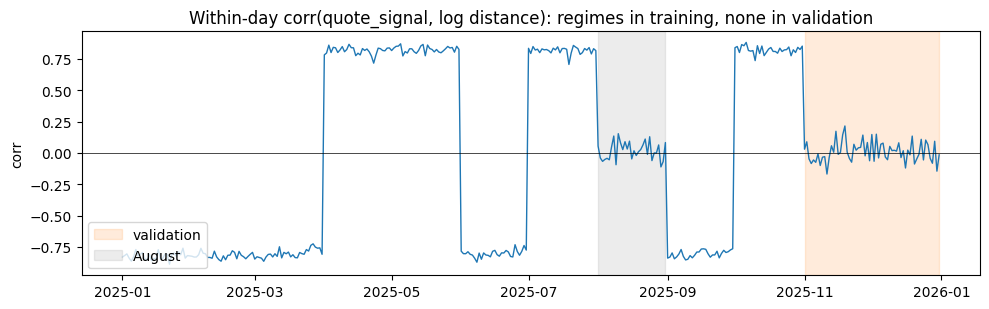

within-day |corr(quote_signal, log $/mile)|: Jan–Jul,Sep–Oct median 0.628 | August median 0.046
within-day |corr(quote_signal, log distance)| median: train ex-Aug 0.816 | validation 0.056


In [5]:
both = pd.concat([train.assign(set="train"), valid.assign(set="validation")])
dc = both.groupby("date").apply(lambda x: x.quote_signal.corr(np.log(x.distance)))
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(dc.index, dc.values, lw=1); ax.axvspan(pd.Timestamp("2025-11-01"), pd.Timestamp("2025-12-31"), color="C1", alpha=.15, label="validation")
ax.axvspan(pd.Timestamp("2025-08-01"), pd.Timestamp("2025-08-31"), color="grey", alpha=.15, label="August")
ax.axhline(0, color="k", lw=.5); ax.legend(loc="lower left")
ax.set(title="Within-day corr(quote_signal, log distance): regimes in training, none in validation", ylabel="corr")
fig.tight_layout(); fig.savefig(FIG / "quote_signal_regimes.png", dpi=130); plt.show()

rpm = np.log(train.posted_rate / train.distance)
day_corr = pd.DataFrame({"qs": train.quote_signal, "rpm": rpm, "date": train.date}).groupby("date").apply(lambda x: x.qs.corr(x.rpm))
print("within-day |corr(quote_signal, log $/mile)|: Jan–Jul,Sep–Oct median",
      day_corr[day_corr.index.month != 8].abs().median().round(3), "| August median", day_corr[day_corr.index.month == 8].abs().median().round(3))
print("within-day |corr(quote_signal, log distance)| median: train ex-Aug", dc[(dc.index < "2025-11-01") & (dc.index.month != 8)].abs().median().round(3),
      "| validation", dc[dc.index >= "2025-11-01"].abs().median().round(3))

In [6]:
def add_daily_context(*frames):
    # Daily market level from *inputs only* (no labels) across train + validation.
    allx = pd.concat([f[["date", "market_index"]] for f in frames])
    return allx.groupby("date").agg(mi_day=("market_index", "mean")).sort_index()

DAY = add_daily_context(train, valid)
EQUIP = {"Dry Van": 0, "Reefer": 1, "Flatbed": 2}
W_FILL = train.weight.abs().median()

def features(d):
    d = d.join(DAY, on="date")
    d["mi"] = d.market_index.fillna(d.mi_day)
    d["w"] = d.weight.abs()
    d["w_cap"] = (d.w >= 47500).astype(int)
    d["ld"] = np.log(d.distance)
    d["equip"] = d.equipment.map(EQUIP)
    d["td"] = (d.date - pd.Timestamp("2025-01-01")).dt.days
    d["dqe"] = (d.date + pd.offsets.QuarterEnd(0) - d.date).dt.days  # days to quarter end
    d["qe_ramp"] = np.clip(21 - d.dqe, 0, 21) / 21  # simple ramp, used for the section 2 figure only
    d["dow"] = d.date.dt.dayofweek
    d["lane"] = d.pickup + ">" + d.delivery
    return d

# Linear part: smooth, extrapolatable effects (trend, distance curve, market, quarter-end, city).
# quote_signal is excluded (section 2b); use_qs=True exists only to show what including it would cost.
HINGES = (35, 28, 21, 14, 7)  # quarter-end ramp: piecewise-linear over the last 5 weeks, separately per equipment

def linear_X(d, use_qs=False, cities=None):
    X = pd.DataFrame({
        "ld": d.ld, "ld2": d.ld ** 2, "mi": d.mi,
        "w": d.w.fillna(W_FILL) / 1e4, "reefer": (d.equip == 1) * 1.0, "flatbed": (d.equip == 2) * 1.0,
        "td": d.td,
    })
    for h in HINGES:
        X[f"qe{h}"] = np.clip(h - d.dqe, 0, None) / h
        X[f"qe{h}_reefer"] = X[f"qe{h}"] * X.reefer
        X[f"qe{h}_flatbed"] = X[f"qe{h}"] * X.flatbed
    if use_qs:
        X["quote_signal"] = d.quote_signal
    if cities:  # origin / destination effects for cities seen in training
        X = pd.concat([X, pd.DataFrame({f"from_{c}": (d.pickup == c) * 1.0 for c in cities} |
                                       {f"to_{c}": (d.delivery == c) * 1.0 for c in cities}, index=d.index)], axis=1)
    return X

# Tree part: non-linear corrections (geography, interactions, daily market). No raw time index.
TREE = ["ld", "mi", "mi_day", "w", "w_cap", "equip", "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon", "dqe", "dow"]

tr = features(train)
y = np.log(tr.posted_rate / tr.distance)  # target: log $/mile

flagged corrupted labels: 677 (1.41%)


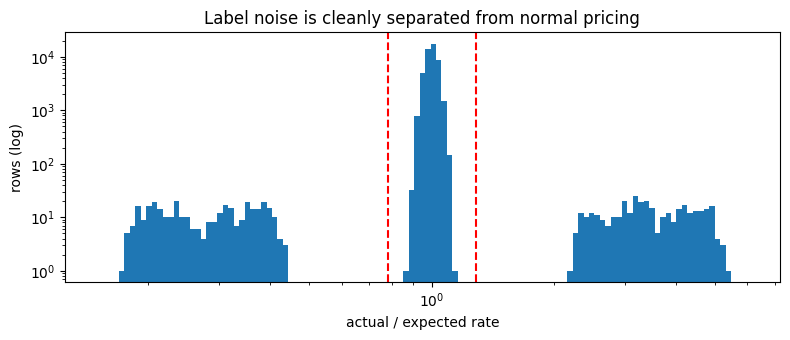

In [7]:
# Flag corrupted labels: fit, drop gross misses, refit, flag |log residual| > 0.25 (~±28%).
r = y - Ridge(1e-3).fit(linear_X(tr), y).predict(linear_X(tr))
keep = r.abs() < 0.25
r = y - Ridge(1e-3).fit(linear_X(tr)[keep], y[keep]).predict(linear_X(tr))
tr["clean"] = r.abs() < 0.25
print("flagged corrupted labels:", (~tr.clean).sum(), f"({(~tr.clean).mean():.2%})")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.exp(r), bins=np.logspace(np.log10(.15), np.log10(6), 120)); ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(np.exp(.25), color="r", ls="--"); ax.axvline(np.exp(-.25), color="r", ls="--")
ax.set(xlabel="actual / expected rate", ylabel="rows (log)", title="Label noise is cleanly separated from normal pricing")
fig.tight_layout(); fig.savefig(FIG / "label_outliers.png", dpi=130); plt.show()

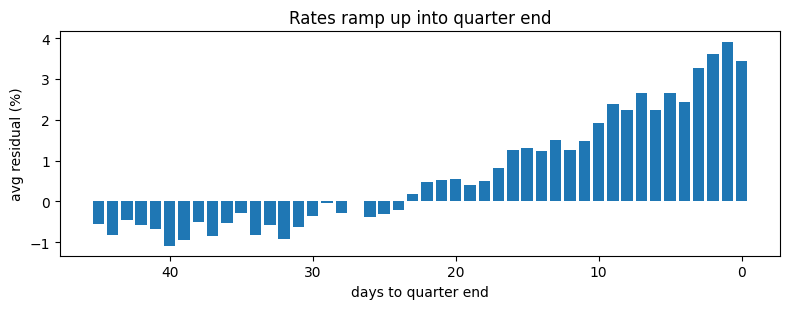

In [8]:
# Quarter-end effect: mean residual (without the quarter-end term) by days to quarter end.
lx = linear_X(tr).filter(regex="^(?!qe)"); c = tr.clean
res = y[c] - Ridge(1e-3).fit(lx[c], y[c]).predict(lx[c])
prof = res.groupby(tr.dqe[c].clip(upper=45)).mean()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(prof.index, prof.values * 100); ax.invert_xaxis()
ax.set(xlabel="days to quarter end", ylabel="avg residual (%)", title="Rates ramp up into quarter end")
fig.tight_layout(); fig.savefig(FIG / "quarter_end.png", dpi=130); plt.show()

## 3. Validation design

The task is **forecasting**: training covers Jan–Oct 2025, the scored set is Nov–Dec 2025. A random split would leak future market
conditions into training and overstate accuracy, so every split here is by time:

- **Primary holdout:** train Jan–Aug, test Sep–Oct. This is the same two-month horizon as the real task and includes a quarter end.
- **Rolling-origin backtest:** for each month Jun–Oct, train on everything before it and test on that month.
- **Unseen-city check:** in the primary holdout, remove 8 random cities from training to mimic the 8 new cities in validation.
- **Validation-like check:** in validation `quote_signal` is noise, so every holdout is also scored with `quote_signal` shuffled within each day. A model that doesn't use the feature gets the same score either way.

Metrics are computed on clean holdout rows (the error we can control) and on all rows (includes the corrupted labels no model can predict).

In [9]:
def make_hgb(cols):
    return HistGradientBoostingRegressor(max_iter=1500, learning_rate=0.03, max_leaf_nodes=31, min_samples_leaf=40,
                                         l2_regularization=1.0, categorical_features=[cols.index("equip")], random_state=SEED)

def lane_effect(fit, resid, test, k=20, folds=5, mask=0.15):
    # Shrunk mean linear residual per lane. Out-of-fold on the training rows so the trees can't memorise their own labels.
    # A random 15% is blanked so the trees learn a good fallback for lanes never seen (unseen-city check: 1.84% → 1.61%).
    enc = lambda f, r, d: d.lane.map(r.groupby(f.lane).sum() / (r.groupby(f.lane).count() + k)).values
    fold = np.arange(len(fit)) % folds
    oof = np.full(len(fit), np.nan)
    for i in range(folds):
        oof[fold == i] = enc(fit[fold != i], resid[fold != i], fit[fold == i])
    oof[np.random.default_rng(SEED).random(len(fit)) < mask] = np.nan
    return oof, enc(fit, resid, test)

def fit_hybrid(fit, use_qs=False, cities=None):
    # Ridge on log $/mile, then gradient boosting on its residuals (+ shrunk lane effect). Returns a predict function.
    yf = np.log(fit.posted_rate / fit.distance)
    lin = Ridge(1e-3).fit(linear_X(fit, use_qs, cities), yf)
    resid = yf - lin.predict(linear_X(fit, use_qs, cities))
    cols = TREE + ["quote_signal"] * use_qs
    F = fit[cols].copy()
    F["lane_te"], _ = lane_effect(fit, resid, fit.iloc[:0])
    hgb = make_hgb(cols).fit(F, resid)
    lane = resid.groupby(fit.lane).sum() / (resid.groupby(fit.lane).count() + 20)
    def predict(d):
        E = d[cols].assign(lane_te=d.lane.map(lane).values)  # unseen lanes → NaN, handled by the trees
        return np.exp(lin.predict(linear_X(d, use_qs, cities)) + hgb.predict(E)) * d.distance.values
    return predict

def fit_routed(fit):
    # Loads whose cities were both seen in training use the model with city effects;
    # loads touching a new city fall back to the geography-only (lat/lon) model.
    origins, dests = set(fit.pickup), set(fit.delivery)
    with_city, geo_only = fit_hybrid(fit, cities=sorted(origins | dests)), fit_hybrid(fit)
    def predict(d):
        known = (d.pickup.isin(origins) & d.delivery.isin(dests)).values
        out = np.empty(len(d))
        if known.any(): out[known] = with_city(d[known])
        if (~known).any(): out[~known] = geo_only(d[~known])
        return out
    return predict

def fit_predict(kind, fit, test):
    # Returns predicted $ for `test` rows. All models predict log $/mile.
    yf = np.log(fit.posted_rate / fit.distance)
    if kind == "baseline":
        b = lambda d: pd.cut(d.distance, [0, 250, 500, 1000, 1500, 2000, 5000])
        med = (fit.posted_rate / fit.distance).groupby([fit.equip, b(fit)], observed=True).median()
        return med.reindex(pd.MultiIndex.from_arrays([test.equip, b(test)])).values * test.distance.values
    if kind == "linear":
        return np.exp(Ridge(1e-3).fit(linear_X(fit), yf).predict(linear_X(test))) * test.distance.values
    if kind == "hgb":
        return np.exp(make_hgb(TREE).fit(fit[TREE], yf).predict(test[TREE])) * test.distance.values
    if kind == "hybrid + quote_signal":
        return fit_hybrid(fit, use_qs=True)(test)
    if kind == "hybrid, geo only":
        return fit_hybrid(fit)(test)
    if kind == "hybrid":
        return fit_routed(fit)(test)

def metrics(pred, test):
    a, c = test.posted_rate.values, test.clean.values
    e = pred - a
    return {"MAE clean": np.abs(e[c]).mean(), "MAPE clean": (np.abs(e[c]) / a[c]).mean(), "RMSE clean": np.sqrt((e[c] ** 2).mean()),
            "bias clean": np.log(a[c] / pred[c]).mean(), "MAE all": np.abs(e).mean(), "MAPE all": (np.abs(e) / a).mean()}

def validation_like(d, seed=SEED):
    # Destroy quote_signal's link to the label (as in Nov–Dec) while keeping its daily distribution.
    rng = np.random.default_rng(seed)
    return d.assign(quote_signal=d.groupby("date").quote_signal.transform(lambda s: rng.permutation(s.values)))

MODELS = ["baseline", "linear", "hgb", "hybrid + quote_signal", "hybrid, geo only", "hybrid"]
fit, test = tr[(tr.date < "2025-09-01") & tr.clean], tr[tr.date >= "2025-09-01"]
holdout = pd.DataFrame({k: {**metrics(fit_predict(k, fit, test), test),
                            "MAPE clean, validation-like": metrics(fit_predict(k, fit, validation_like(test)), test)["MAPE clean"]}
                        for k in MODELS}).T
holdout.style.format({"MAE clean": "{:.1f}", "RMSE clean": "{:.1f}", "MAE all": "{:.1f}", "MAPE clean": "{:.2%}", "MAPE all": "{:.2%}",
                      "bias clean": "{:+.2%}", "MAPE clean, validation-like": "{:.2%}"})

,MAE clean,MAPE clean,RMSE clean,bias clean,MAE all,MAPE all,"MAPE clean, validation-like"
baseline,82.8,3.82%,112.9,+0.81%,138.4,6.32%,3.82%
linear,54.6,2.59%,73.2,+0.45%,110.5,5.11%,2.59%
hgb,86.8,3.65%,118.2,+3.57%,142.3,6.06%,3.65%
hybrid + quote_signal,31.0,1.35%,44.2,+0.38%,87.2,3.88%,1.51%
"hybrid, geo only",32.5,1.38%,46.9,+0.45%,88.6,3.91%,1.38%
hybrid,31.7,1.34%,45.8,+0.45%,87.9,3.87%,1.34%


In [10]:
rows = []
for m in [6, 7, 8, 9, 10]:
    start = pd.Timestamp(2025, m, 1)
    f, t_ = tr[(tr.date < start) & tr.clean], tr[(tr.date >= start) & (tr.date < start + pd.offsets.MonthBegin(1))]
    for k in ["linear", "hgb", "hybrid + quote_signal", "hybrid, geo only", "hybrid"]:
        rows.append({"test month": start.strftime("%b"), "model": k, **metrics(fit_predict(k, f, t_), t_)})
bt = pd.DataFrame(rows)
display(bt.pivot(index="test month", columns="model", values="MAPE clean").loc[["Jun", "Jul", "Aug", "Sep", "Oct"]].style.format("{:.2%}"))
print(bt.groupby("model")[["MAPE clean", "MAPE all"]].mean().round(4))

model,hgb,hybrid,hybrid + quote_signal,"hybrid, geo only",linear
test month,,,,,
Jun,2.31%,1.27%,1.29%,1.30%,2.52%
Jul,2.25%,1.39%,1.46%,1.48%,2.58%
Aug,3.05%,1.32%,2.04%,1.38%,2.58%
Sep,2.07%,1.21%,1.18%,1.25%,2.53%
Oct,5.13%,1.48%,1.48%,1.51%,2.65%


                       MAPE clean  MAPE all
model                                      
hgb                        0.0296    0.0520
hybrid                     0.0133    0.0366
hybrid + quote_signal      0.0149    0.0382
hybrid, geo only           0.0138    0.0372
linear                     0.0257    0.0489


In [11]:
rng = np.random.default_rng(SEED)
cities = sorted(set(tr.pickup) | set(tr.delivery))
drop = set(rng.choice(cities, 8, replace=False))
touch = lambda d: d.pickup.isin(drop) | d.delivery.isin(drop)
f = fit[~touch(fit)]
p = fit_predict("hybrid", f, test)
print("held-out cities:", sorted(drop))
print("MAPE clean on loads touching unseen cities:", f"{metrics(p[touch(test).values], test[touch(test)])['MAPE clean']:.2%}",
      "| other loads:", f"{metrics(p[~touch(test).values], test[~touch(test)])['MAPE clean']:.2%}")

held-out cities: [np.str_('Albuquerque'), np.str_('Amarillo'), np.str_('Austin'), np.str_('Dallas'), np.str_('Detroit'), np.str_('Kansas City'), np.str_('Lubbock'), np.str_('Providence')]
MAPE clean on loads touching unseen cities: 1.61% | other loads: 1.35%


**Model choice: linear + gradient-boosting hybrid, without `quote_signal`, routed by city coverage.**

- Gradient boosting alone cannot extrapolate the upward time drift, so it under-predicts the future.
- A linear model on log $/mile captures the trend, the distance curve, the market index, city effects and a 5-week quarter-end ramp per equipment type. It misses interactions.
- The hybrid fits the linear model first, then boosts on its residuals with no raw time feature. It also gets a shrunk per-lane residual. It keeps the extrapolation and adds the non-linear corrections.
- City effects only exist for known cities, so loads touching a new city are routed to a geography-only twin model that relies on lat/lon (the unseen-city check uses this route).
- Adding `quote_signal` looks better on Sep–Oct, but it fails in August and under validation-like conditions. Those are the conditions of the real predictions, so the final model leaves it out.
- It uses scikit-learn only, so there are no extra dependencies.

## 4. Final model (all clean training data) and predictions

In [12]:
fit_all = tr[tr.clean]
predict = fit_routed(fit_all)

y_all = np.log(fit_all.posted_rate / fit_all.distance)
coef = pd.Series(Ridge(1e-3).fit(linear_X(fit_all), y_all).coef_, linear_X(fit_all).columns)
print(coef[[c for c in coef.index if not c.startswith("qe")]].round(4))
print("trend: {:+.2%} per 30 days".format(np.expm1(coef.td * 30)))
uplift = lambda dqe, eq: sum((coef[f"qe{h}"] + coef.get(f"qe{h}_{eq}", 0)) * max(h - dqe, 0) / h for h in HINGES)
print("quarter-end uplift (linear part, log points) by days to quarter end:")
print(pd.DataFrame({eq: [uplift(x, eq) for x in range(0, 43, 7)] for eq in ["dry van", "reefer", "flatbed"]}, index=range(0, 43, 7)).T.round(3))

ld        -0.2572
ld2        0.0097
mi         0.1422
w          0.0299
reefer     0.1175
flatbed    0.0716
td         0.0002
dtype: float64
trend: +0.59% per 30 days
quarter-end uplift (linear part, log points) by days to quarter end:
            0      7      14     21     28   35   42
dry van  0.028  0.017  0.010  0.005  0.000  0.0  0.0
reefer   0.054  0.036  0.024  0.012  0.003  0.0  0.0
flatbed  0.081  0.059  0.037  0.021  0.007  0.0  0.0


In [13]:
va = features(valid)
va["predicted_rate"] = predict(va).round(2)
out = template[["load_id"]].merge(va[["load_id", "predicted_rate"]], on="load_id", how="left")
assert len(out) == 12_000 and out.predicted_rate.notna().all() and (out.predicted_rate > 0).all()
out.to_csv("validation_predictions.csv", index=False)
print(out.predicted_rate.describe().round(1))

count    12000.0
mean      2391.1
std       1378.2
min        196.4
25%       1292.9
50%       2070.9
75%       3390.8
max       7075.1
Name: predicted_rate, dtype: float64


**December chart inputs.** The fixed rows contain only lane, distance, equipment, weight and date. The remaining features are filled from information that is legitimately available:
- **Coordinates:** each city's lat/lon from training.
- **`market_index`:** that day's mean across the 12,000 validation loads, which are inputs and not labels. `quote_signal` is not used.

In [14]:
coords = pd.concat([train[["pickup", "pickup_lat", "pickup_lon"]].set_axis(["city", "lat", "lon"], axis=1),
                    train[["delivery", "delivery_lat", "delivery_lon"]].set_axis(["city", "lat", "lon"], axis=1)]).groupby("city").first()
d = dec.copy()
d[["pickup_lat", "pickup_lon"]] = coords.loc[d.pickup].values
d[["delivery_lat", "delivery_lon"]] = coords.loc[d.delivery].values
d["market_index"] = d.date.map(DAY.mi_day)
assert d.market_index.notna().all()
dec_out = dec.copy()
dec_out["predicted_rate"] = predict(features(d)).round(2)
dec_out["date"] = dec_out.date.dt.strftime("%Y-%m-%d")
dec_out.to_csv("december_chart_predictions.csv", index=False)

hist = tr[(tr.pickup == "Lexington") & (tr.delivery == "Fort Wayne") & (tr.equipment == "Dry Van") & tr.clean]
print("historical Lexington→Fort Wayne Dry Van rates:", hist.posted_rate.describe()[["count", "min", "mean", "max"]].round(0).to_dict())
dec_out

historical Lexington→Fort Wayne Dry Van rates: {'count': 21.0, 'min': 758.0, 'mean': 823.0, 'max': 934.0}


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,836.59
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,844.14
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,852.82
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,856.54
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,852.38
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,844.31
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,838.35
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,841.29
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,849.09
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,858.49


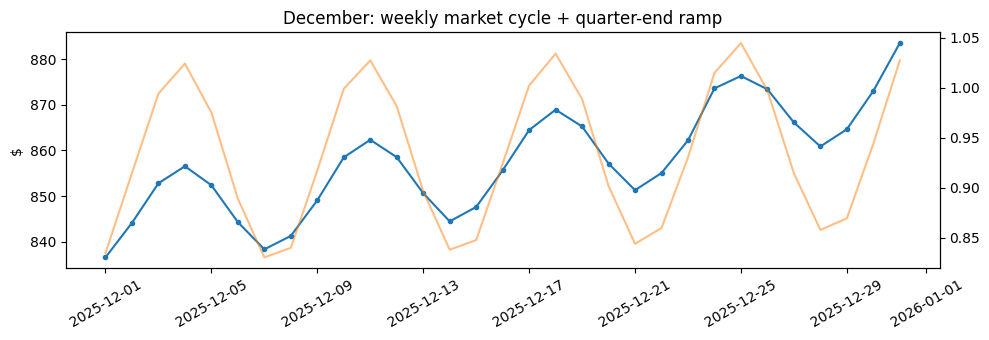

In [15]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(pd.to_datetime(dec_out.date), dec_out.predicted_rate, marker="o", ms=3, label="predicted rate")
ax2 = ax.twinx(); ax2.plot(pd.to_datetime(dec_out.date), d.market_index, color="C1", alpha=.5, label="market_index")
ax.set(title="December: weekly market cycle + quarter-end ramp", ylabel="$"); ax.tick_params(axis="x", rotation=30)
fig.tight_layout(); fig.savefig(FIG / "december_forecast.png", dpi=130); plt.show()